# Plotting Soundings with Observed ACARS data

In [1]:
# import sounderpy
import sounderpy as spy

### **Understanding ACARS functionality** 

- **To get ACARS data, we need to use the** `acars_data()` **class**

- **Reading the documentation on ACARS data access may prove useful before using this notebook: *https://kylejgillett.github.io/sounderpy/reference/gettingdata.html#observed-data-acars-aircraft-profiles***

In [2]:
# First we need to set up a 'connection' to the ACARS data. 
# We do this by creating a variable called `acars_conn` which is set equal
# to the `acars_data()` class. The class needs a year, month, day and hour as strs.

# Lets look for flights on Feb. 28th 2024 at 01 UTC
acars_conn = spy.acars_data('2024', '02', '28', '01')

# Now that we have the connection established, lets look for a profile 
# to plot. We can do this by using the `.list_profiles() function:
acars_conn.list_profiles()

> LIST ACARS PROFILES FUNCTION
  ---------------------------------
> AVAILABLE ACARS PROFILES FOR 2024-02-28 01Z...


> COMPLETE --------
> RUNTIME: 00:00:00


['ATL_0120',
 'ATL_0140',
 'AUS_0130',
 'AUS_0140',
 'BNA_0110',
 'BNA_0140',
 'BOI_0130',
 'BWI_0120',
 'CHS_0100',
 'CMH_0150',
 'DAL_0100',
 'DAL_0130',
 'DTW_0100',
 'FLL_0140',
 'HDN_0120',
 'HOU_0130',
 'HOU_0140',
 'IND_0100',
 'JAN_0120',
 'JAX_0110',
 'LAS_0130',
 'LAS_0150',
 'LAX_0110',
 'LAX_0130',
 'LGA_0140',
 'LGB_0120',
 'MCO_0110',
 'MCO_0150',
 'MDW_0150',
 'MFE_0140',
 'MIA_0120',
 'MSY_0120',
 'OKC_0100',
 'PHX_0120',
 'PHX_0150',
 'SAN_0100',
 'SAT_0110',
 'SAT_0140',
 'SBA_0110',
 'SJC_0130',
 'SLC_0140',
 'TPA_0100',
 'TPA_0110']

In [3]:
# These are all the available flights we can get data from across the ACARS network
# on Feb. 28th 2024 at 01 UTC. Now we can pick one and add it to the function
# `.get_profile()` to actually get the data. Lets try 'SJC_0130':
clean_data = acars_conn.get_profile('SJC_0130')

> ACARS DATA ACCESS FUNCTION
  ---------------------------------


    > COMPLETE --------
    > RUNTIME: 00:00:01
    > SUMMARY: 01:30Z Flight from SJC, Norman Y. Mineta San Jose International Airport at 02-28-2024-01:30Z


 
    > THERMODYNAMICS --------------------------------------------- 
    --- SBCAPE: 0.0 | MUCAPE: 0.0 | MLCAPE: 0.0 | MUECAPE: --
    --- MU 0-3: 0.0 | MU 0-6: 0.0 | SB 0-3: 0.0 | SB 0-6: 0.0
 
    > KINEMATICS ------------------------------------------------- 
    --- 0-500 SRW: 17.9 knot | 0-500 SWV: 0.0 | 0-500 SHEAR: 3.4 | 0-500 SRH: -9.9
    --- 1-3km SRW: 11.9 knot | 1-3km SWV: 0.004 | 1-3km SHEAR: 10.5 | | 1-3km SRH: 17.6
 


In [4]:
# Lets check out the ACARS data that we just accessed
# and stored in the `clean_data` variable: 

# `clean_data` is a python dictionary of 'clean' vertical profile data
# it comes with temperature, dewpoint, pressure, height, u and v
# as well as a number of useful 'meta data'

clean_data

{'p': Quantity(array([1010.28,  985.84,  954.98,  919.68,  880.71,  845.17,  808.79,
         769.16,  732.87,  704.22,  693.73,  640.81,  584.25,  529.53,
         481.79,  435.84,  385.14,  327.46,  286.74,  251.86,  230.16,
         225.53,  204.27]), "hectopascal"),
 'z': Quantity(array([   27.,   233.,   499.,   812.,  1169.,  1506.,  1863.,  2267.,
         2652.,  2967.,  3085.,  3703.,  4411.,  5151.,  5849.,  6576.,
         7454.,  8575.,  9467., 10317., 10895., 11024., 11652.]), "meter"),
 'T': Quantity(array([ 1.485e+01,  1.325e+01,  1.075e+01,  9.550e+00,  8.850e+00,
         6.850e+00,  7.350e+00,  4.350e+00,  2.350e+00,  5.000e-02,
        -4.500e-01, -4.750e+00, -9.450e+00, -1.515e+01, -2.015e+01,
        -2.645e+01, -3.375e+01, -4.325e+01, -5.145e+01, -5.715e+01,
        -6.095e+01, -6.195e+01, -5.845e+01]), "degree_Celsius"),
 'Td': Quantity(array([ 1.580e+00,  1.290e+00,  1.380e+00, -1.050e+00,  6.000e-02,
        -1.621e+01, -1.345e+01, -1.392e+01, -1.544e+01, -1.63

-----

### **Build a plot of the data**

> SOUNDING PLOTTER FUNCTION
  ---------------------------------
    > PREPARING DATA


    > BUILDING SKEW-T LOG-P DIAGRAM
    > BUILDING HODOGRAPH
    > BUILDING MAP INSET


    > RADAR SCAN FOUND: Site: KMUX Scan: 2024-02-28 | 01:28z


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


    > BUILDING ACCESSORY PLOTS
    > PLOTTING SOUNDING PARAMETERS


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


    > FIGURE LOADING...
    > COMPLETE --------
    > RUNTIME: 00:00:12


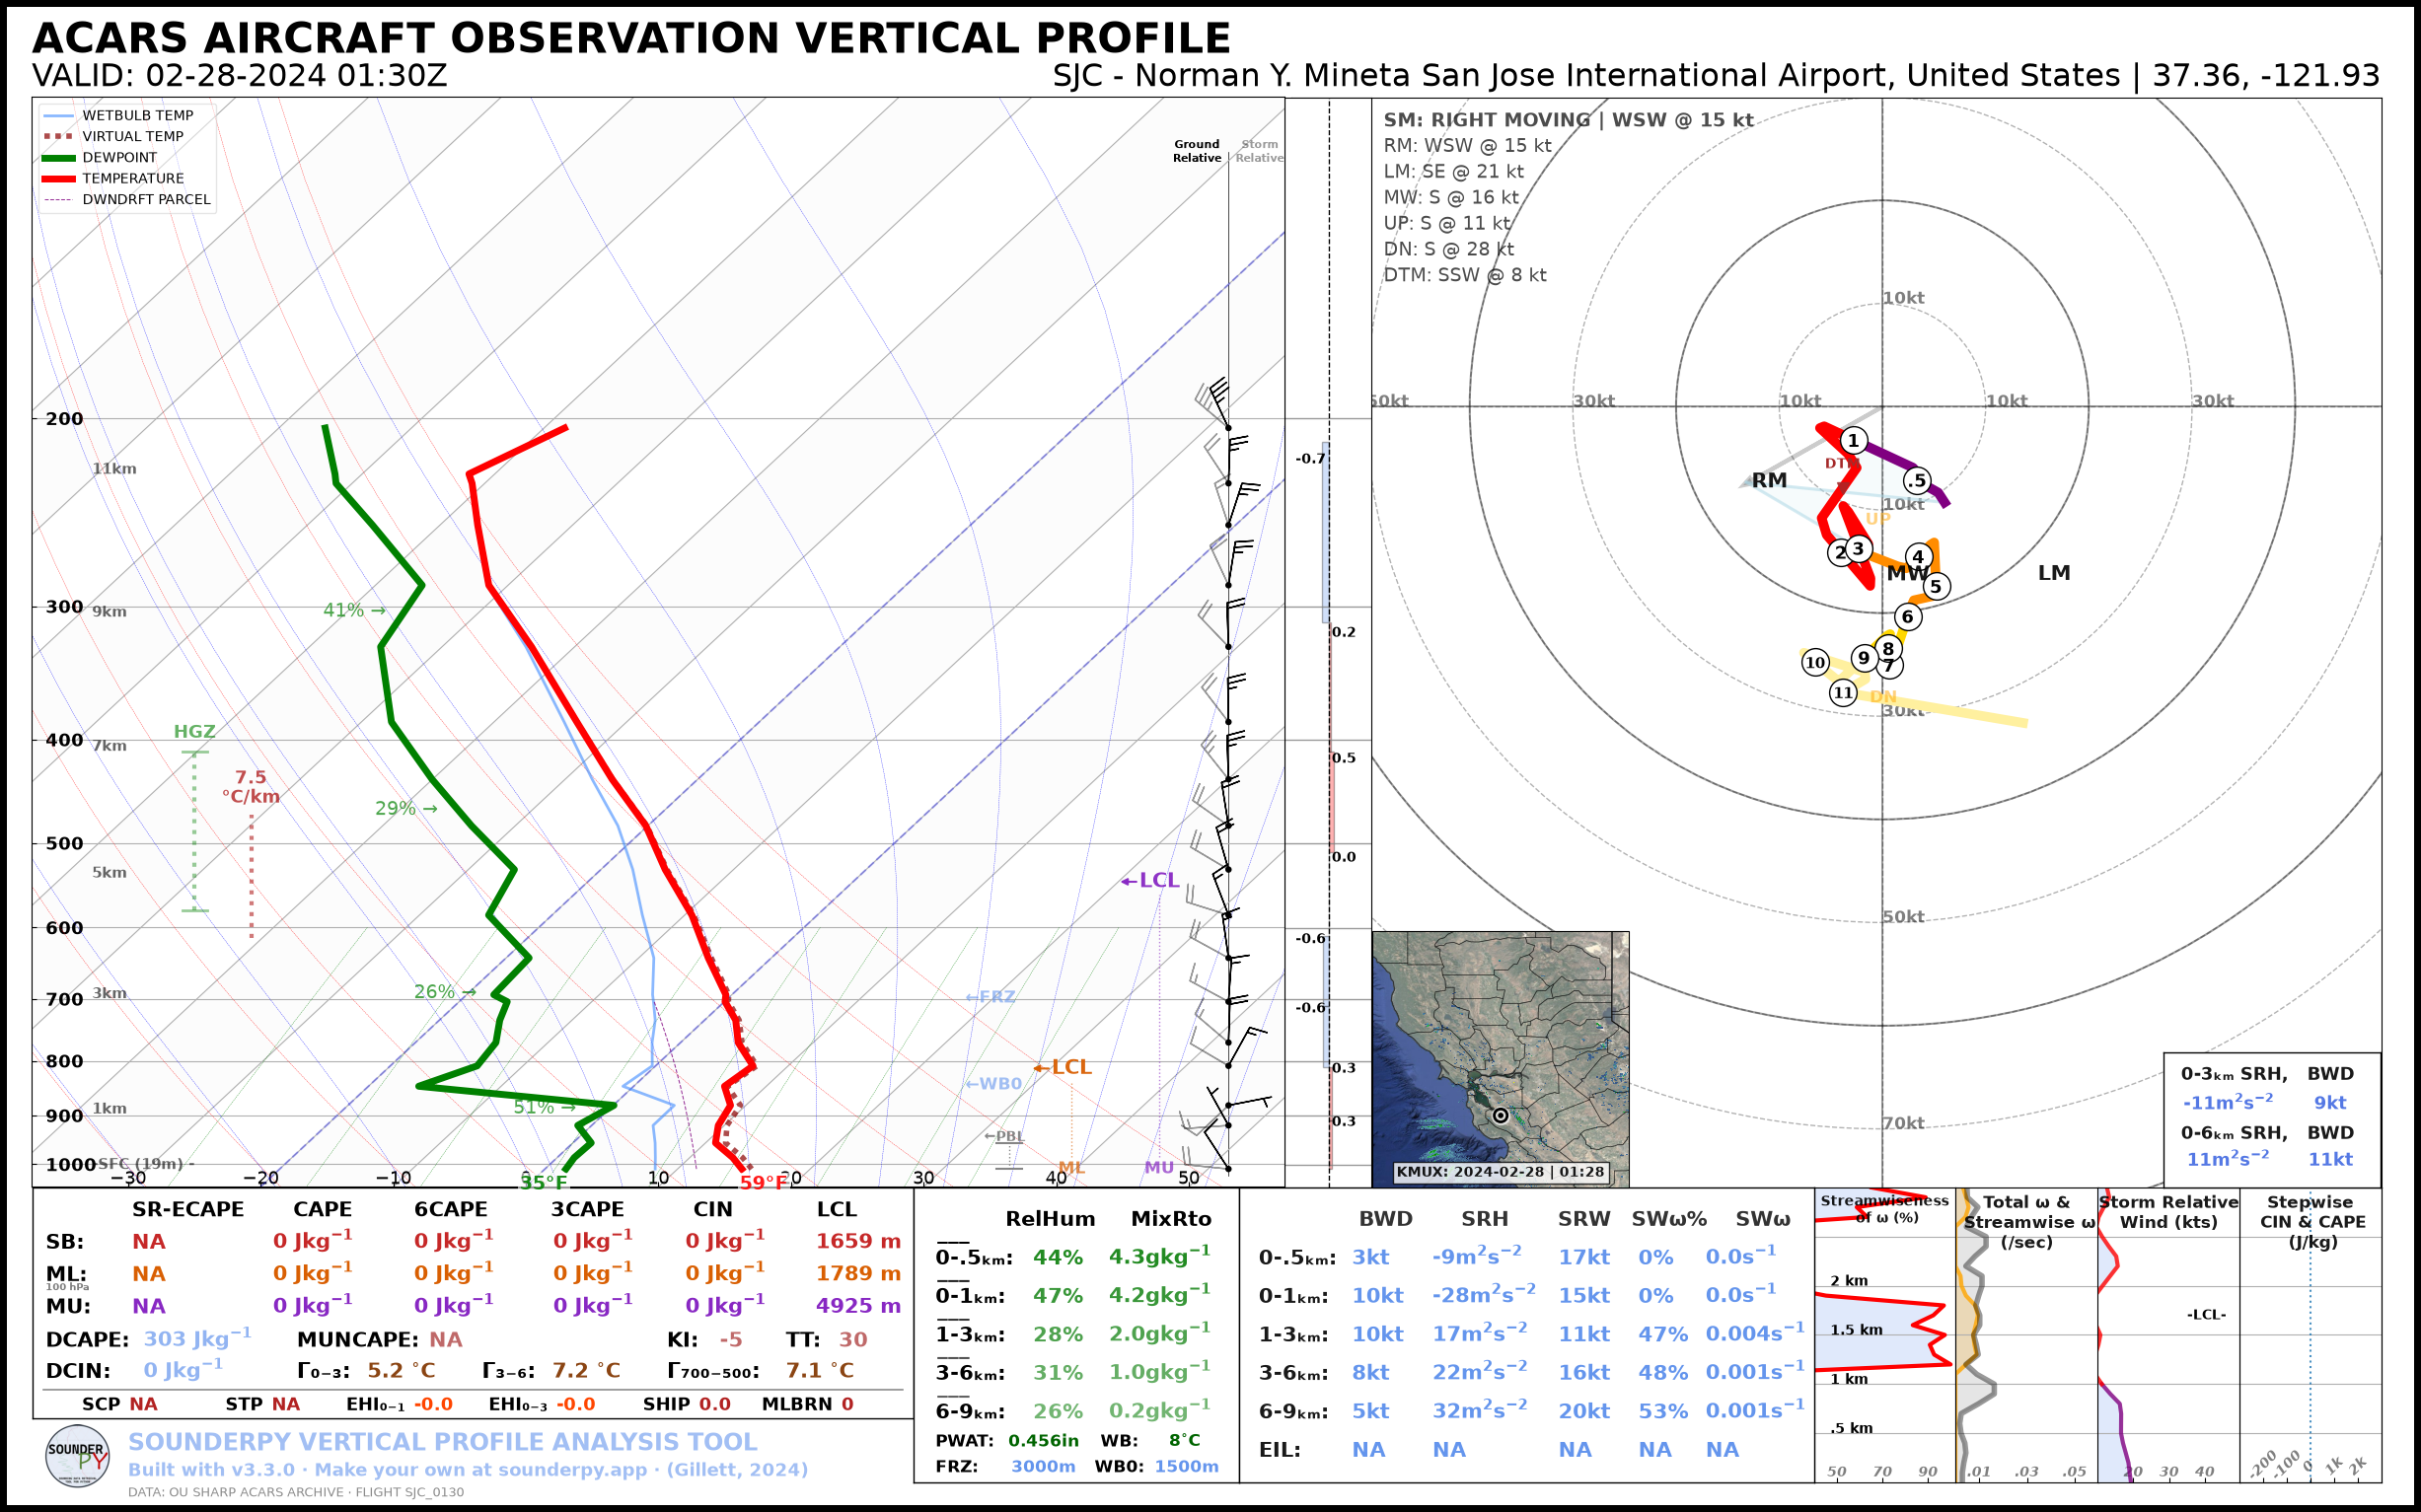

In [5]:
# lets make a sounding!
# radar='single' shows the nearest NEXRAD site's reflectivity on the map.
# The default radar mosaic only keeps about the last month, so it can't cover this date.
spy.build_sounding(clean_data, radar='single')

> HODOGRAPH PLOTTER FUNCTION --
-------------------------------
    > PREPARING DATA


    > BUILDING HODOGRAPH
    > BUILDING MAP INSET


    > RADAR SCAN FOUND: Site: KMUX Scan: 2024-02-28 | 01:28z


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


    > BUILDING ACCESSORY PLOTS
    > PLOTTING PARAMETERS
    > FIGURE LOADING...
    > COMPLETE --------
    > RUNTIME: 00:00:06


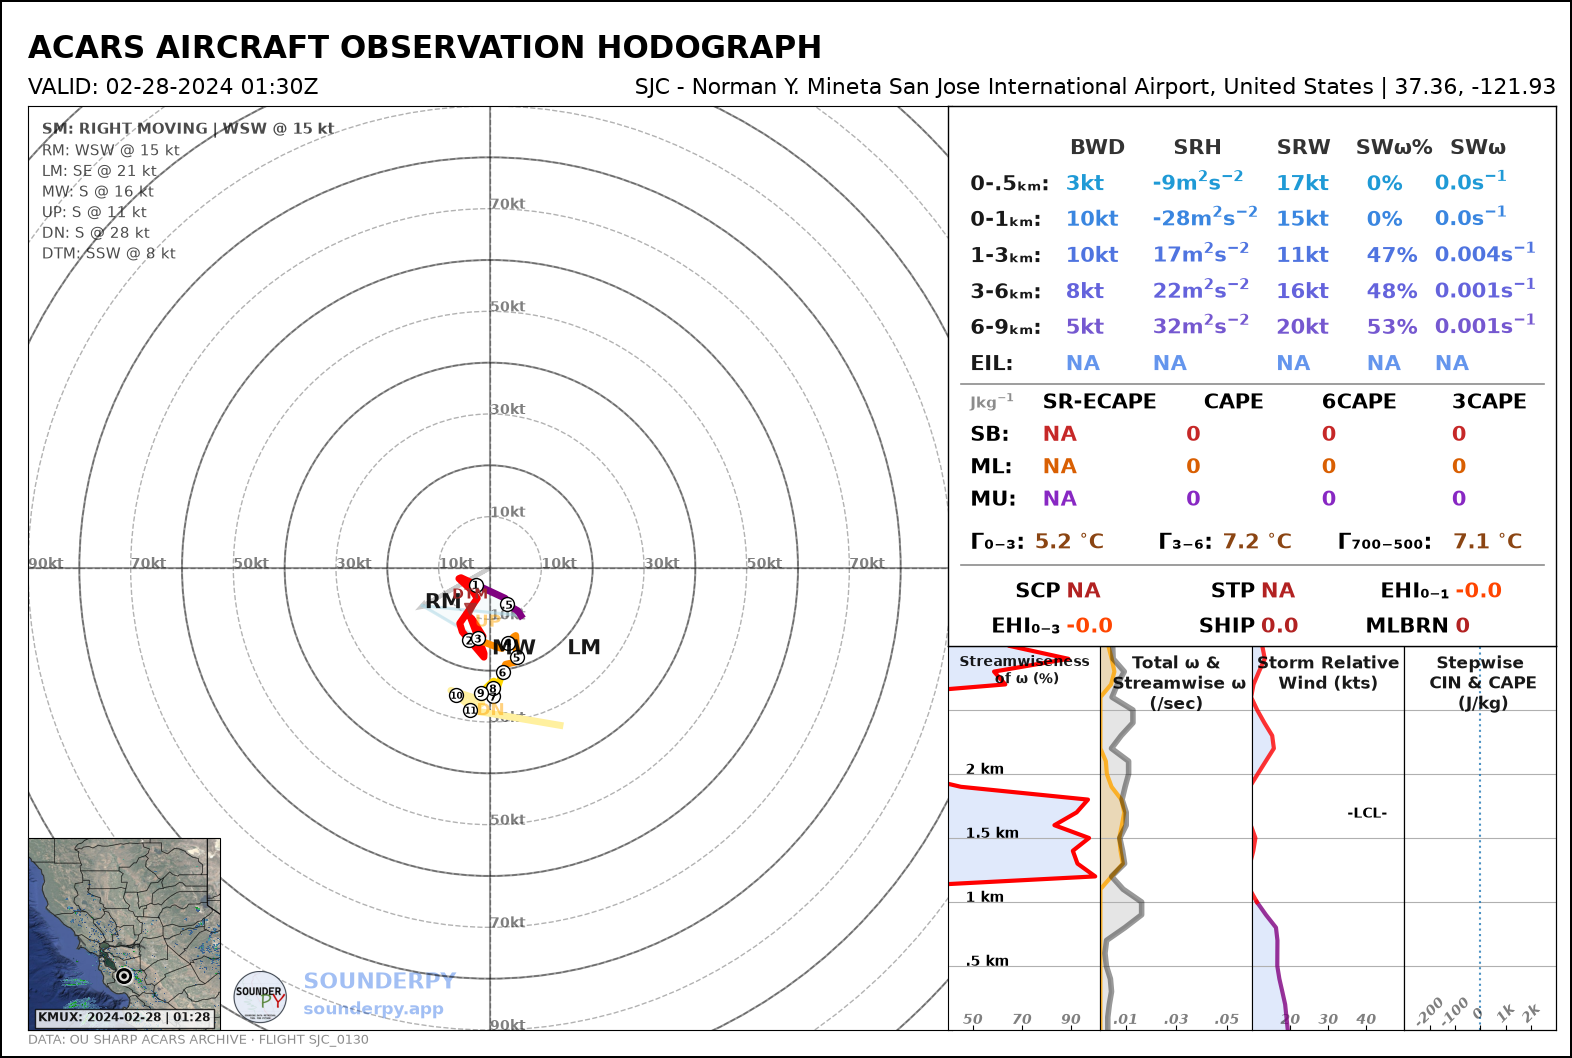

In [6]:
spy.build_hodograph(clean_data, radar='single')